<a href="https://colab.research.google.com/github/yeyevtushenko/Methods-and-Technologies-of-Computational-Intelligence/blob/main/%D0%9C%D0%B5%D1%82%D0%BE%D0%B4%D0%B8_%D1%82%D0%B0_%D1%82%D0%B5%D1%85%D0%BD%D0%BE%D0%BB%D0%BE%D0%B3%D1%96%D1%97_%D0%BE%D0%B1%D1%87%D0%B8%D1%81%D0%BB%D1%8E%D0%B2%D0%B0%D0%BB%D1%8C%D0%BD%D0%BE%D0%B3%D0%BE_%D1%96%D0%BD%D1%82%D0%B5%D0%BB%D0%B5%D0%BA%D1%82%D1%83_%D0%97%D0%9A_61%D0%9F%D0%9C_%D0%84%D0%B2%D1%82%D1%83%D1%88%D0%B5%D0%BD%D0%BA%D0%BE_%D0%B1%D0%B0%D0%B7%D0%BE%D0%B2%D0%B8%D0%B9_%D0%9B%D0%B0%D0%B1%E2%84%9616.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Імпорт бібліотек

In [ ]:
import copy
import random
import time

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torchvision
import matplotlib.pyplot as plt

random.seed(0)
np.random.seed(0)
torch.manual_seed(0)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Пристрій:", device)

Пристрій: cpu


# Завдання 1. Код з теорії, навчання моделі та її покращення

> Зберіть код наведений у теоретичній частині, натренуйте модель, та проаналізуйте результат. Спробуйте його покращити методами, які вам вже знайомі. Наведіть найкращий результат на тесті.

# Рекурентні комірки з теорії

In [ ]:
class SingleRNN(nn.Module):
    def __init__(self, n_inputs, n_neurons):
        super(SingleRNN, self).__init__()
        self.Wx = torch.randn(n_inputs, n_neurons)
        self.Wy = torch.randn(n_neurons, n_neurons)
        self.b = torch.zeros(1, n_neurons)

    def forward(self, X0, X1):
        self.Y0 = torch.tanh(torch.mm(X0, self.Wx) + self.b)
        self.Y1 = torch.tanh(torch.mm(self.Y0, self.Wy) + torch.mm(X1, self.Wx) + self.b)
        return self.Y0, self.Y1

X0_batch = torch.tensor([[0, 1, 2, 0], [3, 4, 5, 0], [6, 7, 8, 0], [9, 0, 1, 0]], dtype=torch.float)
X1_batch = torch.tensor([[9, 8, 7, 0], [0, 0, 0, 0], [6, 5, 4, 0], [3, 2, 1, 0]], dtype=torch.float)
Y0_val, Y1_val = SingleRNN(4, 1)(X0_batch, X1_batch)
print(Y0_val.shape, Y1_val.shape)

X0_batch = torch.tensor([[0, 1, 2], [3, 4, 5], [6, 7, 8], [9, 0, 1]], dtype=torch.float)
X1_batch = torch.tensor([[9, 8, 7], [0, 0, 0], [6, 5, 4], [3, 2, 1]], dtype=torch.float)
Y0_val, Y1_val = SingleRNN(3, 5)(X0_batch, X1_batch)
print(Y0_val.shape, Y1_val.shape)
print(Y1_val)

torch.Size([4, 1]) torch.Size([4, 1])
torch.Size([4, 5]) torch.Size([4, 5])
tensor([[-1.0000, -0.9003,  0.9977, -1.0000, -1.0000],
        [ 0.9786, -0.9153, -0.8691,  0.4201, -0.5865],
        [-1.0000, -0.2084,  0.5394, -0.8647, -1.0000],
        [-0.9992,  0.8741,  0.3005,  0.9813, -0.9994]])


In [ ]:
class CleanBasicRNN(nn.Module):
    def __init__(self, batch_size, n_inputs, n_neurons):
        super(CleanBasicRNN, self).__init__()
        self.rnn = nn.RNNCell(n_inputs, n_neurons)
        self.hx = torch.randn(batch_size, n_neurons)

    def forward(self, X):
        output = []
        for i in range(2):
            self.hx = self.rnn(X[i], self.hx)
            output.append(self.hx)
        return output, self.hx

X_batch = torch.tensor([[[0, 1, 2], [3, 4, 5], [6, 7, 8], [9, 0, 1]],
                        [[9, 8, 7], [0, 0, 0], [6, 5, 4], [3, 2, 1]]], dtype=torch.float)
output_val, states_val = CleanBasicRNN(4, 3, 5)(X_batch)
print(len(output_val), output_val[0].shape, states_val.shape)

2 torch.Size([4, 5]) torch.Size([4, 5])


`SingleRNN` реалізує два часові кроки вручну: на другому кроці вхід `X1` та вихід першого кроку `Y0` перетворюються матрицями `Wx` і `Wy`, а результат проходить через `tanh`. Для 4 екземплярів і 5 нейронів кожен вихід має розмір 4 на 5 (розмір партії на кількість нейронів). У `CleanBasicRNN` ту саму роботу виконує вбудований `nn.RNNCell`; у коді з теорії комірка створювалась як локальна змінна `rnn` у конструкторі і не була доступна в `forward`, тому вона збережена як `self.rnn`.

# Підготовка даних MNIST

In [ ]:
MNIST_train = torchvision.datasets.MNIST('./', download=True, train=True)
MNIST_test = torchvision.datasets.MNIST('./', download=True, train=False)

X_all = (MNIST_train.data.float() / 255.).unsqueeze(1)
y_all = MNIST_train.targets
generator = torch.Generator().manual_seed(0)
permutation = torch.randperm(len(X_all), generator=generator)

X_train, y_train = X_all[permutation[:10000]], y_all[permutation[:10000]]
X_val, y_val = X_all[permutation[10000:12000]], y_all[permutation[10000:12000]]
X_test = (MNIST_test.data.float() / 255.).unsqueeze(1)
y_test = MNIST_test.targets
print(X_train.shape, X_val.shape, X_test.shape)

torch.Size([10000, 1, 28, 28]) torch.Size([2000, 1, 28, 28]) torch.Size([10000, 1, 28, 28])


Для економії часу використовується 10 000 зображень для навчання, 2000 для вибору кращої епохи (валідація) та весь тестовий набір із 10 000 зображень. Кожне зображення 28 на 28 розглядається як послідовність із 28 кроків (рядків) по 28 ознак (пікселів рядка), тобто з `sequence_length = 28` та `input_size = 28`.

# Функції навчання

In [ ]:
class ToSeq(nn.Module):
    def forward(self, x):
        n, c, h, w = x.shape
        return x.permute(0, 2, 1, 3).reshape(n, h, c * w)

def batches(X, y, batch_size, shuffle=False):
    index = torch.randperm(len(X)) if shuffle else torch.arange(len(X))
    for start in range(0, len(X), batch_size):
        part = index[start:start + batch_size]
        yield X[part].to(device), y[part].to(device)

def evaluate(model, X, y):
    model.eval()
    correct = 0
    with torch.no_grad():
        for images, labels in batches(X, y, 1000):
            correct += (model(images).argmax(dim=1) == labels).sum().item()
    return correct / len(X)

def run(name, model, data, epochs=10, lr=0.001, batch_size=64, clip=None, cosine=False, verbose=True):
    X_tr, y_tr, X_v, y_v, X_te, y_te = data
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs) if cosine else None
    best_val, best_state, history, start = -1, None, [], time.time()
    for epoch in range(epochs):
        model.train()
        total = 0.0
        for images, labels in batches(X_tr, y_tr, batch_size, shuffle=True):
            loss = criterion(model(images), labels)
            optimizer.zero_grad()
            loss.backward()
            if clip:
                nn.utils.clip_grad_norm_(model.parameters(), clip)
            optimizer.step()
            total += loss.item() * len(labels)
        if scheduler:
            scheduler.step()
        val_acc = evaluate(model, X_v, y_v)
        history.append((total / len(X_tr), val_acc))
        if val_acc > best_val:
            best_val, best_state = val_acc, copy.deepcopy(model.state_dict())
        if verbose:
            print(f'{name} | епоха {epoch + 1}/{epochs}: loss {history[-1][0]:.4f}, val acc {val_acc:.4f}')
    model.load_state_dict(best_state)
    test_acc = evaluate(model, X_te, y_te)
    print(f'{name} | кращий val acc {best_val:.4f}, test acc {test_acc:.4f}, {time.time() - start:.0f} с')
    return {'val acc': best_val, 'test acc': test_acc, 'params': sum(p.numel() for p in model.parameters()),
            'time': time.time() - start, 'history': history, 'model': model}

def summary(results):
    return pd.DataFrame({n: {'val acc': r['val acc'], 'test acc': r['test acc'], 'параметрів': r['params'],
                             'час, с': round(r['time'])} for n, r in results.items()}).T

mnist = (X_train, y_train, X_val, y_val, X_test, y_test)

# Модель з теорії

In [ ]:
sequence_length = 28
input_size = 28
hidden_size = 128
num_layers = 2
num_classes = 10

class RNN(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers, num_classes):
        super(RNN, self).__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.gru = nn.GRU(input_size, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device)
        out, _ = self.gru(x, h0)
        out = self.fc(out[:, -1, :])
        return out

results1 = {}
torch.manual_seed(0)
results1['модель з теорії (GRU, lr 0.01, 1 епоха)'] = run(
    'теорія', nn.Sequential(ToSeq(), RNN(input_size, hidden_size, num_layers, num_classes)), mnist,
    epochs=1, lr=0.01)

теорія | епоха 1/1: loss 0.7194, val acc 0.9090


теорія | кращий val acc 0.9090, test acc 0.9100, 3 с


Модель взята з теорії без змін: два шари `nn.GRU` з 128 нейронами, на виході повнозв'язний шар від прихованого стану останнього часового кроку, `CrossEntropyLoss`, Adam з `lr=0.01`, 1 епоха. Назва класу в теорії `RNN`, але всередині використовується GRU, тому саме цю модель можна вважати початковим варіантом.

# Покращення моделі

In [ ]:
def make(kind='GRU', **kwargs):
    return nn.Sequential(ToSeq(), RecurrentNet(kind, **kwargs))

class RecurrentNet(nn.Module):
    def __init__(self, kind='GRU', input_size=28, hidden_size=128, num_layers=2, num_classes=10,
                 bidirectional=False, dropout=0.0, layer_norm=False, head_dropout=0.0):
        super(RecurrentNet, self).__init__()
        layer = {'RNN': nn.RNN, 'GRU': nn.GRU, 'LSTM': nn.LSTM}[kind]
        self.hidden_size = hidden_size
        self.bidirectional = bidirectional
        self.rnn = layer(input_size, hidden_size, num_layers, batch_first=True,
                         dropout=dropout, bidirectional=bidirectional)
        out_size = hidden_size * (2 if bidirectional else 1)
        self.norm = nn.LayerNorm(out_size) if layer_norm else nn.Identity()
        self.drop = nn.Dropout(head_dropout)
        self.fc = nn.Linear(out_size, num_classes)

    def forward(self, x):
        out, _ = self.rnn(x, None)
        if self.bidirectional:
            last = torch.cat([out[:, -1, :self.hidden_size], out[:, 0, self.hidden_size:]], dim=1)
        else:
            last = out[:, -1, :]
        return self.fc(self.drop(self.norm(last)))

torch.manual_seed(0)
results1['GRU, lr 0.001, 10 епох'] = run('GRU 10 епох', make('GRU'), mnist, epochs=10, lr=0.001)
torch.manual_seed(0)
results1['+ обрізання градієнтів (1.0) та косинусний розклад lr'] = run(
    'GRU clip+cosine', make('GRU'), mnist, epochs=10, lr=0.002, clip=1.0, cosine=True)
torch.manual_seed(0)
results1['+ 256 нейронів'] = run(
    'GRU 256', make('GRU', hidden_size=256), mnist, epochs=10, lr=0.002, clip=1.0, cosine=True)
print(summary(results1).round(4).to_string())
best1 = max(results1, key=lambda n: results1[n]['val acc'])
print('Найкращий за валідацією:', best1, ', test acc =', results1[best1]['test acc'])

GRU 10 епох | епоха 1/10: loss 1.1969, val acc 0.8415


GRU 10 епох | епоха 2/10: loss 0.3873, val acc 0.9150


GRU 10 епох | епоха 3/10: loss 0.2490, val acc 0.9380


GRU 10 епох | епоха 4/10: loss 0.1973, val acc 0.9505


GRU 10 епох | епоха 5/10: loss 0.1559, val acc 0.9535


GRU 10 епох | епоха 6/10: loss 0.1280, val acc 0.9530


... (23 outputs left out)

GRU 256 | епоха 8/10: loss 0.0077, val acc 0.9850


GRU 256 | епоха 9/10: loss 0.0044, val acc 0.9845


GRU 256 | епоха 10/10: loss 0.0035, val acc 0.9840


GRU 256 | кращий val acc 0.9850, test acc 0.9845, 44 с
                                                       val acc  test acc  параметрів  час, с
модель з теорії (GRU, lr 0.01, 1 епоха)                 0.9090    0.9100    161034.0     3.0
GRU, lr 0.001, 10 епох                                  0.9730    0.9699    161034.0    22.0
+ обрізання градієнтів (1.0) та косинусний розклад lr   0.9845    0.9777    161034.0    22.0
+ 256 нейронів                                          0.9850    0.9845    616970.0    44.0
Найкращий за валідацією: + 256 нейронів , test acc = 0.9845


Модель з теорії (GRU, `lr=0.01`, 1 епоха) дала точність 0.910 на тесті: за одну епоху на 10 000 зображеннях вона ще недонавчена. Збільшення до 10 епох з `lr=0.001` підняло результат до 0.970. Обрізання градієнтів за нормою 1.0 (проти вибуху градієнта, описаного в теорії) та косинусний розклад швидкості навчання дали 0.978, а збільшення кількості нейронів у шарі зі 128 до 256 дало найкращий результат: **0.9845** на тесті (0.985 на валідації) при вдвічі більшому часі навчання (44 с проти 22 с). Тестовий набір складається з 10 000 зображень, тож розкид одного запуску становить порядку 0.2 п.п., і різниця між 0.970 та 0.984 помітна, а між близькими варіантами ні.

# Завдання 2. Порівняння RNN, GRU та LSTM

> Спробуйте інші архітектури рекурентних мереж, такі як GRU та LSTM (nn.GRU та nn.LSTM). Для GRU достатньо просто замінити комірку. А для LSTM необхідно подати 2 скритих стани lstm_out, (h_n, hc) = self.lstm(X, None). Проаналізуйте результат. Чи покращилися значення? Яка модель дала кращий результат?

RNN | кращий val acc 0.9575, test acc 0.9553, 8 с


GRU | кращий val acc 0.9845, test acc 0.9777, 22 с


LSTM | кращий val acc 0.9800, test acc 0.9764, 28 с
      val acc  test acc  параметрів  час, с
RNN    0.9575    0.9553     54538.0     8.0
GRU    0.9845    0.9777    161034.0    22.0
LSTM   0.9800    0.9764    214282.0    28.0


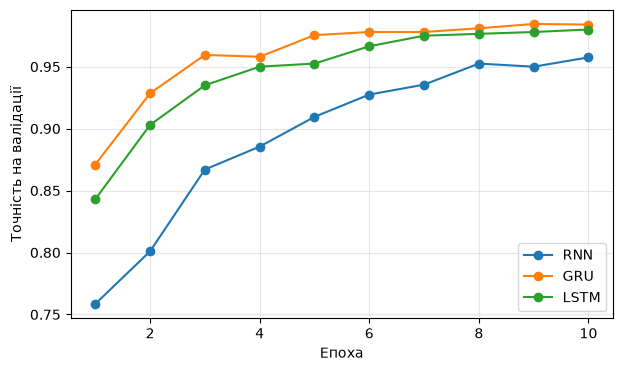

In [ ]:
results2 = {}
for kind in ['RNN', 'GRU', 'LSTM']:
    torch.manual_seed(0)
    results2[kind] = run(kind, make(kind), mnist, epochs=10, lr=0.002, clip=1.0, cosine=True, verbose=False)
print(summary(results2).round(4).to_string())

plt.figure(figsize=(7, 4))
for kind, r in results2.items():
    plt.plot(range(1, 11), [h[1] for h in r['history']], marker='o', label=kind)
plt.xlabel('Епоха')
plt.ylabel('Точність на валідації')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Із однаковими налаштуваннями (2 шари, 128 нейронів, 10 епох) на тесті вийшло: RNN 0.9553, GRU 0.9777, LSTM 0.9764. Найгірша класична RNN з tanh, у неї також найменше параметрів (54 тис.) і найшвидше навчання (8 с). GRU і LSTM помітно кращі (+2.2 п.п.), що відповідає теорії: вони створені для розв'язання проблеми зникаючого градієнта і краще пам'ятають вплив ранніх рядків зображення. Між собою GRU та LSTM відрізняються на 0.13 п.п. на тесті (0.0045 на валідації на користь GRU), що менше за розкид одного запуску. Проте GRU має на чверть менше параметрів (161 тис. проти 214 тис.) і навчається швидше (22 с проти 28 с), тому для цієї задачі вона практичніша.

# Завдання 3. Двонаправлена мережа

> Спробуйте реалізувати двонаправлену RNN модель (додати ключ bidirectional=True) в nn.RNN(…, bidirectional=True). Як треба змінити вхід та розміри? Спробуйте реалізувати та отримати результат.

In [ ]:
results3 = {}
for kind in ['RNN', 'GRU', 'LSTM']:
    torch.manual_seed(0)
    results3[kind + ', двонаправлена'] = run(kind + ' bi', make(kind, bidirectional=True), mnist, epochs=10,
                                              lr=0.002, clip=1.0, cosine=True, verbose=False)
print(summary({**{k + ', однонаправлена': v for k, v in results2.items()}, **results3}).round(4).to_string())

model = make('GRU', bidirectional=True).to(device)
images = X_train[:5].to(device)
out, h_n = model[1].rnn(model[0](images))
print('вхід:', tuple(model[0](images).shape), ', вихід rnn:', tuple(out.shape), ', h_n:', tuple(h_n.shape),
      ', вхід fc:', tuple(model[1].fc.weight.shape))

RNN bi | кращий val acc 0.9670, test acc 0.9686, 16 с


GRU bi | кращий val acc 0.9800, test acc 0.9814, 48 с


LSTM bi | кращий val acc 0.9840, test acc 0.9783, 60 с
                      val acc  test acc  параметрів  час, с
RNN, однонаправлена    0.9575    0.9553     54538.0     8.0
GRU, однонаправлена    0.9845    0.9777    161034.0    22.0
LSTM, однонаправлена   0.9800    0.9764    214282.0    28.0
RNN, двонаправлена     0.9670    0.9686    141834.0    16.0
GRU, двонаправлена     0.9800    0.9814    420362.0    48.0
LSTM, двонаправлена    0.9840    0.9783    559626.0    60.0
вхід: (5, 28, 28) , вихід rnn: (5, 28, 256) , h_n: (4, 5, 128) , вхід fc: (10, 256)


Для двонаправленої мережі (`bidirectional=True`) вхід залишається того самого розміру (партія, 28 кроків, 28 ознак), а вихід `rnn` має розмір (партія, 28, 2 · 128), бо виходи прямого та зворотного проходів з'єднуються за останньою віссю; стан `h_n` має форму (2 · кількість шарів, партія, 128). Тому вхід повнозв'язного шару змінюється зі 128 до 256 (див. форму ваг `fc` (10, 256)). Для останнього рядка беруться прямий вихід останнього кроку та зворотний вихід першого кроку (зворотний прохід завершується саме на першому кроці, і в останньому кроці він побачив лише один рядок). Результати на тесті: RNN 0.9686 (було 0.9553), GRU 0.9814 (було 0.9777), LSTM 0.9783 (було 0.9764). Двонаправленість найбільше допомагає слабкій класичній RNN (+1.3 п.п.), для GRU та LSTM виграш порівнянний з розкидом одного запуску, а параметрів і часу потрібно приблизно вдвічі більше.

# Завдання 4. Нормалізація та dropout

> Додайте шар нормалізації та dropout (можна просто вказати ключ True в середині nn.RNN()). Чи поліпшився результат?

In [ ]:
base_kind = max(results2, key=lambda k: results2[k]['val acc'])
print('Базова архітектура для завдання 4:', base_kind)
variants = {
    'без змін': dict(),
    'dropout між шарами (0.3)': dict(dropout=0.3),
    'LayerNorm': dict(layer_norm=True),
    'LayerNorm + dropout між шарами + dropout перед fc': dict(layer_norm=True, dropout=0.3, head_dropout=0.3),
}
results4 = {}
for title, kw in variants.items():
    torch.manual_seed(0)
    results4[title] = run(title, make(base_kind, **kw), mnist, epochs=10, lr=0.002, clip=1.0, cosine=True, verbose=False)
print(summary(results4).round(4).to_string())

Базова архітектура для завдання 4: GRU


без змін | кращий val acc 0.9845, test acc 0.9777, 21 с


dropout між шарами (0.3) | кращий val acc 0.9805, test acc 0.9762, 22 с


LayerNorm | кращий val acc 0.9865, test acc 0.9816, 21 с


LayerNorm + dropout між шарами + dropout перед fc | кращий val acc 0.9835, test acc 0.9800, 22 с
                                                   val acc  test acc  параметрів  час, с
без змін                                            0.9845    0.9777    161034.0    21.0
dropout між шарами (0.3)                            0.9805    0.9762    161034.0    22.0
LayerNorm                                           0.9865    0.9816    161290.0    21.0
LayerNorm + dropout між шарами + dropout перед fc   0.9835    0.9800    161290.0    22.0


Базовою вибрана GRU (найкраща з завдання 2 за валідацією). Dropout 0.3 між шарами не покращив результат (0.9762 проти 0.9777), що очікувано: за 10 епох на 10 000 зображеннях мережа ще не перенавчається настільки, щоб регуляризація допомагала. Шар нормалізації `LayerNorm` на виході рекурентної частини дав найкращий результат (val 0.9865, test 0.9816 проти 0.9777), але це +0.4 п.п. одним запуском, тож покращення слабке. Поєднання LayerNorm і двох dropout дало 0.9800 на тесті.

# Завдання 5. CIFAR10 та CIFAR100

> Спробуйте адаптувати модель із цього завдання для вирішення набору даних CIFAR10 та CIFAR100. Проаналізуйте результат. Чи краще він ніж отриманий із згортковими мережами та повнозв'язними?

In [ ]:
CIFAR10_train = torchvision.datasets.CIFAR10('./', download=True, train=True)
CIFAR10_test = torchvision.datasets.CIFAR10('./', download=True, train=False)
CIFAR100_train = torchvision.datasets.CIFAR100('./', download=True, train=True)
CIFAR100_test = torchvision.datasets.CIFAR100('./', download=True, train=False)

def cifar_data(train, test, seed=0):
    X = torch.FloatTensor(train.data).permute(0, 3, 1, 2) / 255.
    y = torch.LongTensor(train.targets)
    Xt = torch.FloatTensor(test.data).permute(0, 3, 1, 2) / 255.
    yt = torch.LongTensor(test.targets)
    mean = X.mean(dim=(0, 2, 3), keepdim=True)
    std = X.std(dim=(0, 2, 3), keepdim=True)
    X, Xt = (X - mean) / std, (Xt - mean) / std
    generator = torch.Generator().manual_seed(seed)
    p = torch.randperm(len(X), generator=generator)
    pt = torch.randperm(len(Xt), generator=generator)
    return (X[p[:10000]], y[p[:10000]], X[p[10000:12000]], y[p[10000:12000]], Xt[pt[:2000]], yt[pt[:2000]])

cifar10 = cifar_data(CIFAR10_train, CIFAR10_test)
cifar100 = cifar_data(CIFAR100_train, CIFAR100_test)
print([t.shape for t in cifar10])

0.0%

0.0%

0.1%

0.1%

0.1%

0.1%

... (5,149 outputs left out)

100.0%

100.0%

100.0%

[torch.Size([10000, 3, 32, 32]), torch.Size([10000]), torch.Size([2000, 3, 32, 32]), torch.Size([2000]), torch.Size([2000, 3, 32, 32]), torch.Size([2000])]


Зображення CIFAR розмірами 3 на 32 на 32 перетворюються на послідовність із 32 кроків (рядків зображення), на кожному кроці подається 96 ознак (3 канали по 32 пікселі). Як і в попередніх роботах, використовується 10 000 зображень для навчання, 2000 для валідації та 2000 для тесту, а значення нормуються за середнім та стандартним відхиленням каналів.

In [ ]:
def mlp(num_classes):
    return nn.Sequential(nn.Flatten(), nn.Linear(3072, 512), nn.ReLU(), nn.Linear(512, 256), nn.ReLU(),
                         nn.Linear(256, num_classes))

def cnn(num_classes):
    return nn.Sequential(
        nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Flatten(), nn.Linear(128 * 4 * 4, 256), nn.ReLU(), nn.Linear(256, num_classes))

best_kw = results4[max(results4, key=lambda t: results4[t]['val acc'])]
best_title = max(results4, key=lambda t: results4[t]['val acc'])
kw = variants[best_title]
print('Налаштування рекурентної мережі:', base_kind, kw)

results5 = {}
for ds_name, data, classes in [('CIFAR10', cifar10, 10), ('CIFAR100', cifar100, 100)]:
    torch.manual_seed(0)
    results5[ds_name + ': ' + base_kind + ' (як у завданні 4)'] = run(
        ds_name + ' ' + base_kind, make(base_kind, input_size=96, num_classes=classes, **kw), data,
        epochs=15, lr=0.002, clip=1.0, cosine=True, verbose=False)
    torch.manual_seed(0)
    results5[ds_name + ': двонаправлена ' + base_kind] = run(
        ds_name + ' bi ' + base_kind, make(base_kind, input_size=96, num_classes=classes, bidirectional=True, **kw), data,
        epochs=15, lr=0.002, clip=1.0, cosine=True, verbose=False)
    torch.manual_seed(0)
    results5[ds_name + ': повнозв\'язна'] = run(ds_name + ' MLP', mlp(classes), data, epochs=15, lr=0.001,
                                                  clip=1.0, cosine=True, verbose=False)
    torch.manual_seed(0)
    results5[ds_name + ': згорткова'] = run(ds_name + ' CNN', cnn(classes), data, epochs=15, lr=0.001,
                                             clip=1.0, cosine=True, verbose=False)
print(summary(results5).round(4).to_string())

Налаштування рекурентної мережі: GRU {'layer_norm': True}


CIFAR10 GRU | кращий val acc 0.5080, test acc 0.5195, 36 с


CIFAR10 bi GRU | кращий val acc 0.5255, test acc 0.5455, 76 с


CIFAR10 MLP | кращий val acc 0.4755, test acc 0.4690, 8 с


CIFAR10 CNN | кращий val acc 0.6705, test acc 0.6640, 78 с


CIFAR100 GRU | кращий val acc 0.2140, test acc 0.2090, 36 с


CIFAR100 bi GRU | кращий val acc 0.2255, test acc 0.2210, 76 с


CIFAR100 MLP | кращий val acc 0.1960, test acc 0.2040, 8 с


CIFAR100 CNN | кращий val acc 0.2985, test acc 0.3095, 78 с
                                 val acc  test acc  параметрів  час, с
CIFAR10: GRU (як у завданні 4)    0.5080    0.5195    187402.0    36.0
CIFAR10: двонаправлена GRU        0.5255    0.5455    473098.0    76.0
CIFAR10: повнозв'язна             0.4755    0.4690   1707274.0     8.0
CIFAR10: згорткова                0.6705    0.6640    620362.0    78.0
CIFAR100: GRU (як у завданні 4)   0.2140    0.2090    199012.0    36.0
CIFAR100: двонаправлена GRU       0.2255    0.2210    496228.0    76.0
CIFAR100: повнозв'язна            0.1960    0.2040   1730404.0     8.0
CIFAR100: згорткова               0.2985    0.3095    643492.0    78.0


Для CIFAR зображення подаються як послідовність із 32 рядків по 96 ознак. Рекурентна мережа (GRU з LayerNorm) дала 0.520 на CIFAR10 та 0.209 на CIFAR100, а двонаправлена 0.546 та 0.221. Для порівняння, повнозв'язна мережа (3072 → 512 → 256 → виходи) дала 0.469 та 0.204, а проста згорткова (три згорткові шари) 0.664 та 0.310. Отже, рекурентна мережа краща за повнозв'язну на CIFAR10 (+5 п.п., з двонаправленою +8 п.п.) і лише трохи краща на CIFAR100 (+0.5 та +1.7 п.п., на тесті з 2000 зображень це в межах розкиду), але суттєво гірша за згорткову (на 14 п.п., для двонаправленої на 12 п.п., на CIFAR10 і на 10 та 9 п.п. на CIFAR100). Причина в тому, що RNN обробляє зображення рядок за рядком і не використовує двовимірну локальну структуру так, як згортка, тому на кольорових зображеннях з великою різноманітністю вона поступається. Усе виконано на підвибірці по 15 епох одним запуском.

# Висновки

У цьому практикумі ми навчились будувати та навчати рекурентні нейронні мережі: комірки RNN (`SingleRNN`, `nn.RNNCell`), багатошарові `nn.RNN`, `nn.GRU` та `nn.LSTM` для класифікації зображень, що розглядаються як послідовності рядків, а також двонаправлені мережі та мережі з нормалізацією та dropout. Метою роботи було засвоїти принцип роботи та побудови рекурентних нейронних мереж, і її досягнуто. Усі експерименти виконано на підвибірці (10 000 зображень для навчання) одним запуском.

**Вибір оптимальних параметрів.** На MNIST найкращий результат дала GRU з 256 нейронами в двох шарах, швидкістю навчання 0.002 з косинусним розкладом, обрізанням градієнтів за нормою 1.0 і 10 епохами: 0.9845 на тесті. Модель з теорії (1 епоха, `lr=0.01`) дала лише 0.910, тобто найбільше значення мало збільшення тривалості навчання та зниження швидкості навчання. GRU та LSTM (0.978 та 0.976) значно кращі за класичну RNN (0.955), а GRU простіша й швидша за LSTM. Двонаправленість покращила слабку RNN (+1.3 п.п.), для GRU та LSTM різниця в межах розкиду одного запуску. LayerNorm дав невелике покращення (0.9816 проти 0.9777), а dropout не допоміг.

**CIFAR.** Рекурентна мережа (0.52 на CIFAR10, двонаправлена 0.55) краща за повнозв'язну (0.47), але значно гірша за згорткову (0.66); на CIFAR100 результати 0.21, 0.22, 0.20 та 0.31 відповідно. Тому для зображень краще використовувати згорткові мережі, а рекурентні призначені для даних, де порядок елементів у послідовності є природним (текст, часові ряди).

# Контрольні питання

**1. Що являє собою рекурентна нейронна мережа?**

Ідея рекурентної нейронної мережі (RNN) полягає у використанні послідовної інформації. У традиційній мережі всі входи та виходи вважаються незалежними один від одного, але для багатьох завдань (наприклад, передбачення наступного слова в реченні) це погана ідея, бо потрібно знати попередні слова. RNN називається рекурентною, оскільки виконує одне й те саме завдання для кожного елемента послідовності, при цьому вихід залежить від попередніх обчислень, а мережа має «пам'ять», яка зберігає інформацію про попередні кроки. Поточний стан обчислюється як h_t = tanh(W_hh · h_(t-1) + W_xh · x_t), а вихід як y_t = W_hy · h_t (за потреби з softmax), причому ті самі ваги застосовуються на кожному часовому кроці, тому довжина послідовності не обмежена. Навчається RNN за допомогою зворотного поширення похибки у часі (BPTT): мережу розгортають в усі часові кроки, помилки на кроках сумуються, а градієнти для спільних ваг комбінуються. Основні проблеми це зникання градієнта (внесок давніх кроків стає незначним, довготривалі залежності ігноруються) та вибух градієнта. Проти зникання допомагають функція ReLU та архітектури LSTM і GRU, проти вибуху урізаний BPTT, обрізання градієнтів за порогом та RMSprop. Перевага RNN в тому, що вона моделює послідовності даних (часові ряди), недолік у складності навчання та неможливості обробляти дуже довгі послідовності з tanh чи ReLU.

**2. Які різновиди рекурентних нейронних мереж існують?**

За співвідношенням довжин входу та виходу розрізняють: one to one (звичайна мережа прямого поширення, RNN не потрібна, наприклад класифікація зображення), one to many (вихід у вигляді послідовності, наприклад опис зображення, де CNN поєднується з RNN), many to one (послідовний вхід та один вихід, наприклад аналіз настроїв речення, а також класифікація зображень, розглянута в цій роботі), many to many (послідовність на вході та виході різної довжини, наприклад машинний переклад) та синхронізований many to many (кожному елементу входу відповідає елемент виходу, наприклад позначення кожного кадру відео). За будовою комірки розрізняють класичну RNN, LSTM (з додатковим станом комірки cell memory, у PyTorch `nn.LSTM` вимагає два початкові приховані стани h0 і c0) та GRU (спрощений варіант, у PyTorch `nn.GRU`), які створені для розв'язання проблеми зникаючого градієнта. Також мережі можуть бути багатошаровими (параметр `num_layers`), двонаправленими (`bidirectional=True`), з dropout між шарами.